# Exploratory Data Analysis — Human / AI / Fusion Text Classification

**Task:** Classify English and German texts as `human`, `ai`, or `fusion` (human text partially rewritten by an LLM).
**Data:** `train.csv` (~272k labeled rows), `test.csv` (25k rows).
**Metric:** Macro-F1 over the three classes.

**Goal of this notebook:** Understand class balance (by language and domain), text-length distributions, and what distinguishes `fusion` from the other two classes — and translate these findings into concrete modeling decisions (truncation length, class weighting, validation strategy, feature ideas).

## 1. Setup and Data Loading

We load the training data and inspect the schema (column names, dtypes, missing values) before any analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 300)
pd.set_option("display.width", 160)

train = pd.read_csv("/kaggle/input/competitions/ai-generated-text-detection-hw3-ucu-ai-2026/train.csv")
print("Shape:", train.shape)
print("Columns:", train.columns.tolist())
print(train.dtypes)
display(train.head(3))

print("Null text:", train["text"].isna().sum())
print("Empty text:", (train["text"].fillna("").str.strip() == "").sum())
print("Label counts:\n", train["label"].value_counts())

Shape: (272352, 5)
Columns: ['id', 'text', 'lang', 'domain', 'label']
id        object
text      object
lang      object
domain    object
label     object
dtype: object


,id,text,lang,domain,label
0,e7adad,"Diego's Demons Return: Is the Football Legend Losing Control? Fans have been left heartbroken and bewildered as whispers swirl about Diego Maradona's health and personal life taking a dramatic turn for the worse. Could the legendary Argentine footballer, once hailed as a hero, be slipping back i...",en-EN,cnn_news,ai
1,3bab63,"Herr Präsident! Meine Damen und Herren! Es wird Sie nicht völlig verwundern, wenn ich nach drei Jahren Regierungszeit, nachdem drei Viertel dieser Regierungszeit vergangen sind, positive Bilanz ziehe für den Bundesinnenminister, gerade für die Felder Migration und innere Sicherheit. Ich will das...",de-DE,bundestag,human
2,4e6c1f,"Frau Präsidentin! Liebe Kolleginnen und Kollegen! Dem Kollegen Kühn stimme ich in Bezug auf das, was er am Anfang gesagt hat, zu. Wir haben in der Tat eine extrem schwere Krise. Eigentlich ist es bewundernswert, mit welcher Disziplin, mit welchem Verantwortungsbewusstsein und wie solidarisch ein...",de-DE,bundestag,human


Null text: 0
Empty text: 0
Label counts:
 label
ai        121940
fusion     83682
human      66730
Name: count, dtype: int64


## 2. Class Balance

### 2.1 Overall distribution

Macro-F1 weights each class **equally**, so even a rare class (likely `fusion`) dominates the score. We check how balanced the classes are overall.

label
ai        0.4477
fusion    0.3073
human     0.2450
Name: proportion, dtype: float64


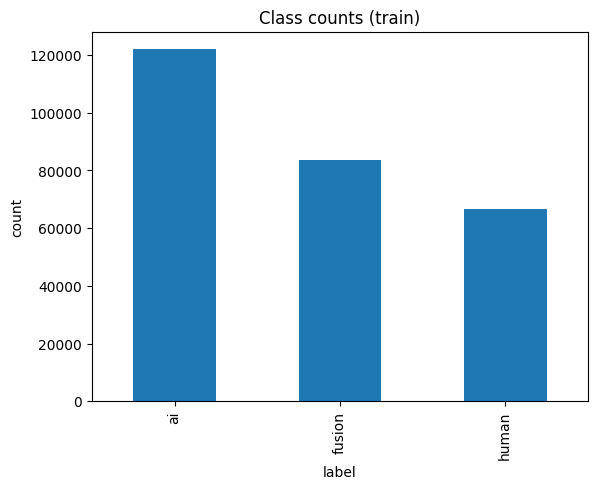

In [2]:
overall = train["label"].value_counts(normalize=True).round(4)
print(overall)
train["label"].value_counts().plot(kind="bar", title="Class counts (train)")
plt.ylabel("count"); plt.show()

### 2.2 Class balance by language

The dataset mixes **English and German**. If the label distribution differs by language, a model could exploit language as a shortcut, and per-language performance may differ. This informs whether we need language-aware validation or features.

In [3]:
if "lang" in train.columns:
    print(pd.crosstab(train["lang"], train["label"], normalize="index").round(3))
    print("\nCounts:")
    print(pd.crosstab(train["lang"], train["label"]))
else:
    print("No 'language' column — check schema in Step 1.")

label     ai  fusion  human
lang                       
de-DE  0.385   0.340  0.275
en-EN  0.463   0.299  0.238

Counts:
label      ai  fusion  human
lang                        
de-DE   20337   17924  14510
en-EN  101603   65758  52220


### 2.3 Class balance by domain

Texts come from news, scientific papers, blogs, parliamentary debates, court cases, student essays, and books. We check the label mix per domain. Domains that are almost entirely one class act as **shortcut signals** — motivating domain-stratified validation so our macro-F1 estimate is honest.

In [4]:
if "domain" in train.columns:
    print(pd.crosstab(train["domain"], train["label"], normalize="index").round(3))
    print("\nCounts:")
    print(pd.crosstab(train["domain"], train["label"]))
else:
    print("No 'domain' column — check schema.")

label                      ai  fusion  human
domain                                      
arxiv_papers            0.843   0.128  0.028
blog_authorship_corpus  0.387   0.306  0.307
bundestag               0.382   0.342  0.277
cnn_news                0.440   0.257  0.302
euro_court_cases        0.404   0.368  0.228
gutenberg               0.915   0.051  0.034
house_of_commons        0.480   0.302  0.218
student_essays          0.399   0.370  0.231

Counts:
label                      ai  fusion  human
domain                                      
arxiv_papers            12050    1833    407
blog_authorship_corpus  15684   12397  12466
bundestag               19977   17887  14479
cnn_news                19488   11402  13395
euro_court_cases        11141   10160   6277
gutenberg                6719     378    247
house_of_commons        15298    9608   6953
student_essays          21583   20017  12506


## 3. Text Length Distributions

Transformer `max_length` is a **token** budget, so word/character lengths tell us where truncation will bite. We examine lengths overall, per class, and per domain. **Fusion** texts (human + LLM rewrite) are expected to be longer and more likely to be truncated — which motivates an explicit long-text strategy.

         n_chars                                                          n_words                                                 
           count    mean     std   min     25%     50%     75%      max     count   mean    std   min    25%    50%    75%     max
label                                                                                                                             
ai      121940.0  3285.8  2030.7  87.0  1802.0  3112.0  4418.0  22646.0  121940.0  493.5  294.3  20.0  287.0  465.0  657.0  2996.0
fusion   83682.0  3636.5  3269.0  92.0  1561.0  2778.0  4493.0  34876.0   83682.0  585.2  530.5  20.0  263.0  445.0  695.0  3000.0
human    66730.0  3492.1  2876.7  76.0  1483.0  2909.0  4628.0  21376.0   66730.0  577.9  473.4  20.0  262.0  481.0  740.0  2998.0

Word-count percentiles (overall):
  50th: 463 words
  75th: 686 words
  90th: 974 words
  95th: 1263 words
  99th: 2450 words


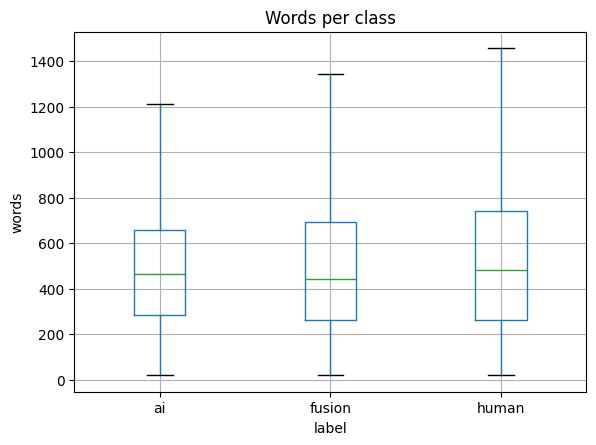


Median words by domain:
domain
blog_authorship_corpus    131.0
student_essays            363.0
bundestag                 512.0
house_of_commons          540.0
cnn_news                  548.0
euro_court_cases          633.0
gutenberg                 706.0
arxiv_papers              888.0
Name: n_words, dtype: float64


In [5]:
train["n_chars"] = train["text"].str.len()
train["n_words"] = train["text"].str.split().str.len()

print(train.groupby("label")[["n_chars", "n_words"]].describe().round(1))

print("\nWord-count percentiles (overall):")
for q in [0.5, 0.75, 0.9, 0.95, 0.99]:
    print(f"  {int(q*100)}th: {train['n_words'].quantile(q):.0f} words")

train.boxplot(column="n_words", by="label", showfliers=False)
plt.suptitle(""); plt.ylabel("words"); plt.title("Words per class")
plt.show()

if "domain" in train.columns:
    print("\nMedian words by domain:")
    print(train.groupby("domain")["n_words"].median().sort_values())

## 4. Examples of Each Class

We inspect sample texts per class. The key question is **"What makes `fusion` different?"** — look for style inconsistency, register mismatch, preserved human artifacts next to polished LLM spans, and mixed structure. These observations motivate later experiments (sentence-level features, stylometry, perplexity).

In [6]:
for lab in ["human", "ai", "fusion"]:
    print(f"\n===== {lab.upper()} =====")
    for t in train[train["label"] == lab]["text"].sample(3, random_state=0):
        print("---")
        print(t[:800].replace("\n", " "))


===== HUMAN =====
---
Islamic State has renewed its call for followers to carry out lone wolf killings of Australians and citizens from four other countries in the alliance against the militant group. The jihad group's latest call to arms in its propaganda magazine, Dabiq, was headlined, 'Rush to Support Your State, O Muslim'. The article said it is very important that attacks take place in every country that has entered into the alliance against the Islamic State, especially the US, UK, France, Australia and Germany. Scroll down for video . The article 'Rush to Support Your State, O Muslim', released in the jihad group's propaganda magazine, Dabiq, calls on Muslims to act out violent killings on citizens from Australia, UK, US, Germany and France . 'Every Muslim should get out of his house, find a crusader and
---
the stupid mp3 isn't working yet. Sorry. We played at the Coquile Valley BPOE #1935 Annual Golf Tournament on Saturday. It went pretty well, considering.. ... that we got c

## 5. Lexical and Stylistic Probes

Cheap style signals: vocabulary richness (type-token ratio) and punctuation usage. If AI text is systematically "cleaner" and fusion sits **between** human and AI, that is direct quantitative evidence that fusion is a blend — and a candidate stylometric feature set.

In [7]:
import re

train["_nw"] = train["n_words"].clip(lower=1)

# Type-token ratio
train["ttr"] = train["n_words"] / train["text"].str.split().apply(lambda w: len(set(w)))

print("Median TTR and word count by class:")
print(train.groupby("label")[["ttr", "n_words"]].median().round(3))

# Punctuation counts (fixed: re.escape to avoid regex errors on '...')
markers = {
    "em_dash": "—",
    "semicolon": ";",
    "exclaim": "!",
    "question": "?",
    "ellipsis": "...",
    "comma": ",",
}

print("\nMean punctuation count per text by class:")
for name, ch in markers.items():
    rate = train.groupby("label")["text"].apply(
        lambda s: s.str.count(re.escape(ch)).mean()
    )
    print(f"  {name:10s}: {rate.round(3).to_dict()}")

# Length-normalized rates (per 1,000 words) — better for comparing style
for name, ch in markers.items():
    train[f"rate_{name}"] = train["text"].str.count(re.escape(ch)) / train["_nw"] * 1000

print("\nPunctuation per 1,000 words, median by class:")
print(train.groupby("label")[[f"rate_{k}" for k in markers]].median().round(2))

# Quick monotonicity check: does ai < fusion < human hold?
med = train.groupby("label")[["ttr"] + [f"rate_{k}" for k in markers]].median()
print("\nMonotone ai<fusion<human?")
for c in med.columns:
    a, f, h = med.loc["ai", c], med.loc["fusion", c], med.loc["human", c]
    print(f"  {c:16s}: {a:.3f} < {f:.3f} < {h:.3f}  -> {a < f < h}")

Median TTR and word count by class:
          ttr  n_words
label                 
ai      1.640    465.0
fusion  1.713    445.0
human   1.801    481.0

Mean punctuation count per text by class:
  em_dash   : {'ai': 0.29, 'fusion': 0.099, 'human': 0.056}
  semicolon : {'ai': 0.52, 'fusion': 0.941, 'human': 1.007}
  exclaim   : {'ai': 1.278, 'fusion': 1.108, 'human': 1.128}
  question  : {'ai': 1.787, 'fusion': 1.163, 'human': 1.343}
  ellipsis  : {'ai': 0.116, 'fusion': 0.452, 'human': 0.581}
  comma     : {'ai': 29.929, 'fusion': 30.243, 'human': 28.633}

Punctuation per 1,000 words, median by class:
        rate_em_dash  rate_semicolon  rate_exclaim  rate_question  rate_ellipsis  rate_comma
label                                                                                       
ai               0.0             0.0           0.0            0.0            0.0       59.18
fusion           0.0             0.0           0.0            0.0            0.0       46.93
human            0.0

## 6. Sanity Checks

Before modeling we verify there are no duplicated texts with conflicting labels, flag very short/noisy texts, and confirm the label set is exactly `human`, `ai`, `fusion`.

In [8]:
dup = train["text"].duplicated(keep=False)
print("Duplicate texts:", int(dup.sum()))
if dup.any():
    print(train[dup].groupby("text")["label"].nunique().value_counts())

print("Very short texts (<10 words):", int((train["n_words"] < 10).sum()))
print("Labels:", sorted(train["label"].unique()))

Duplicate texts: 0
Very short texts (<10 words): 0
Labels: ['ai', 'fusion', 'human']


## 7. Fixed Validation Split and Training Subsample

Per the assignment: **keep the sample fixed when comparing models.** We create (once, with a fixed seed):
- a **stratified validation set** (15%) — used for *all* model comparisons;
- a stratified **transformer training subsample** (40k rows) — enough for a transformer, fits the GPU budget;
- the remaining **training pool** for the baseline.

Stratification is by `label × language × domain` so the validation set mirrors the real distribution.

In [9]:
from sklearn.model_selection import train_test_split

SEED = 42

lang = train["language"].astype(str) if "language" in train.columns else pd.Series("na", index=train.index)
dom  = train["domain"].astype(str)   if "domain"   in train.columns else pd.Series("na", index=train.index)

strat_key = train["label"].astype(str) + "|" + lang + "|" + dom
counts = strat_key.value_counts()
strat_key = strat_key.where(strat_key.map(counts) >= 2, "rare")

tr_idx, va_idx = train_test_split(
    train.index, test_size=0.15, random_state=SEED, stratify=strat_key
)
train_split, val_split = train.loc[tr_idx], train.loc[va_idx]

sub, _ = train_test_split(
    train_split, train_size=40_000, random_state=SEED, stratify=train_split["label"]
)

train_split.to_csv("train_pool.csv", index=False)
val_split.to_csv("val_fixed.csv", index=False)
sub.to_csv("train_transformer_40k.csv", index=False)

print("pool:", len(train_split), "| val:", len(val_split), "| sub:", len(sub))
print("val label balance:\n", val_split["label"].value_counts(normalize=True).round(3))

pool: 231499 | val: 40853 | sub: 40000
val label balance:
 label
ai        0.448
fusion    0.307
human     0.245
Name: proportion, dtype: float64


## 8. Tokenizer-aware truncation check (feeds the encoder design)

In [10]:
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained("xlm-roberta-base")

# Tokenize a sample (fast enough on CPU)
sample = train.sample(8000, random_state=42).copy()
sample["n_tokens"] = sample["text"].map(lambda t: len(tok.encode(t, add_special_tokens=False)))

print("Token-count percentiles by language:")
print(sample.groupby("lang")["n_tokens"].describe(percentiles=[.5,.75,.9,.95,.99]).round(0))

surv512  = (sample["n_tokens"] <= 512).mean()
surv1024 = (sample["n_tokens"] <= 1024).mean()
surv2048 = (sample["n_tokens"] <= 2048).mean()
print(f"\nDocs fully fitting: 512→{surv512:.1%} | 1024→{surv1024:.1%} | 2048→{surv2048:.1%}")

# Per class at 512 and 1024, to see if fusion gets truncated disproportionately
for lim in [512, 1024]:
    print(f"\n% docs fitting within {lim} tokens, by class:")
    print(sample.assign(fit=sample["n_tokens"]<=lim).groupby("label")["fit"].mean().round(3))

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (720 > 512). Running this sequence through the model will result in indexing errors


Token-count percentiles by language:
        count   mean    std   min    50%     75%     90%     95%     99%     max
lang                                                                            
de-DE  1536.0  818.0  401.0  30.0  784.0  1013.0  1264.0  1466.0  2030.0  4253.0
en-EN  6464.0  775.0  664.0  25.0  620.0   999.0  1484.0  1947.0  3570.0  6115.0

Docs fully fitting: 512→35.8% | 1024→76.2% | 2048→96.2%

% docs fitting within 512 tokens, by class:
label
ai        0.314
fusion    0.401
human     0.385
Name: fit, dtype: float64

% docs fitting within 1024 tokens, by class:
label
ai        0.772
fusion    0.765
human     0.739
Name: fit, dtype: float64


## Per-domain TTR (robustness of your best finding)

In [11]:
ttr_by_dom = train.groupby(["domain","label"])["ttr"].median().unstack().round(3)
print(ttr_by_dom)
print("\nMonotone ai<fusion<human in how many domains?")
mono = (ttr_by_dom["ai"] < ttr_by_dom["fusion"]) & (ttr_by_dom["fusion"] < ttr_by_dom["human"])
print(mono.sum(), "/", len(mono))
print(ttr_by_dom[mono])

label                      ai  fusion  human
domain                                      
arxiv_papers            2.024   2.458  2.366
blog_authorship_corpus  1.220   1.313  1.351
bundestag               1.615   1.673  1.660
cnn_news                1.635   1.730  1.869
euro_court_cases        1.862   2.227  2.465
gutenberg               1.710   1.950  1.901
house_of_commons        1.728   1.860  1.990
student_essays          1.556   1.722  2.008

Monotone ai<fusion<human in how many domains?
5 / 8
label                      ai  fusion  human
domain                                      
blog_authorship_corpus  1.220   1.313  1.351
cnn_news                1.635   1.730  1.869
euro_court_cases        1.862   2.227  2.465
house_of_commons        1.728   1.860  1.990
student_essays          1.556   1.722  2.008


## Per-sentence style variance for fusion (the "mixed style" probe)

In [12]:
import re

def sent_ttr_std(text):
    sents = [s for s in re.split(r"(?<=[.!?])\s+", text) if len(s.split()) >= 5]
    if len(sents) < 4:
        return np.nan
    ttrs = [len(s.split()) / max(1, len(set(s.split()))) for s in sents]
    return float(np.std(ttrs))

# Sample to keep it fast
s = train.sample(15000, random_state=42).copy()
s["sent_ttr_std"] = s["text"].map(sent_ttr_std)
print(s.groupby("label")["sent_ttr_std"].agg(["median","mean"]).round(3))
print("\nBy class and domain:")
print(s.groupby(["domain","label"])["sent_ttr_std"].median().unstack().round(3))

        median   mean
label                
ai       0.054  0.055
fusion   0.073  0.079
human    0.077  0.110

By class and domain:
label                      ai  fusion  human
domain                                      
arxiv_papers            0.063   0.113  0.116
blog_authorship_corpus  0.035   0.065  0.069
bundestag               0.050   0.064  0.066
cnn_news                0.056   0.062  0.069
euro_court_cases        0.067   0.098  0.100
gutenberg               0.065   0.089  0.082
house_of_commons        0.056   0.088  0.097
student_essays          0.048   0.075  0.082


In [13]:
from sklearn.model_selection import train_test_split

SEED = 42
strat_key = train["label"] + "|" + train["lang"] + "|" + train["domain"]
counts = strat_key.value_counts()
strat_key = strat_key.where(strat_key.map(counts) >= 2, "rare")

tr_idx, va_idx = train_test_split(train.index, test_size=0.15, random_state=SEED, stratify=strat_key)
train_split, val_split = train.loc[tr_idx], train.loc[va_idx]
sub, _ = train_test_split(train_split, train_size=40_000, random_state=SEED, stratify=train_split["label"])

train_split.to_csv("train_pool.csv", index=False)
val_split.to_csv("val_fixed.csv", index=False)
sub.to_csv("train_transformer_40k.csv", index=False)

print("pool:", len(train_split), "| val:", len(val_split), "| sub:", len(sub))
print("\nval label balance:", val_split["label"].value_counts(normalize=True).round(3).to_dict())
print("\nval lang mix:", val_split["lang"].value_counts(normalize=True).round(3).to_dict())
print("\nval domain×label (row-normalized):")
print(pd.crosstab(val_split["domain"], val_split["label"], normalize="index").round(3))

pool: 231499 | val: 40853 | sub: 40000

val label balance: {'ai': 0.448, 'fusion': 0.307, 'human': 0.245}

val lang mix: {'en-EN': 0.806, 'de-DE': 0.194}

val domain×label (row-normalized):
label                      ai  fusion  human
domain                                      
arxiv_papers            0.843   0.128  0.028
blog_authorship_corpus  0.387   0.306  0.307
bundestag               0.382   0.342  0.277
cnn_news                0.440   0.257  0.302
euro_court_cases        0.404   0.368  0.228
gutenberg               0.916   0.051  0.034
house_of_commons        0.480   0.302  0.218
student_essays          0.399   0.370  0.231


# Explicit EDA Conclusions

## 1. Dataset and data quality

The dataset contains **272,352 labeled training texts** across 5 columns (`id`, `text`, `lang`, `domain`, `label`). Labels are exactly `human`, `ai`, `fusion` — lowercase, as required by the submission format. There are **no null texts, no empty texts, no duplicate texts, and no texts under 10 words**. No cleaning or filtering is required; we can train on the full data without preprocessing decisions that could introduce leakage.

---

## 2. Class balance

Overall distribution:

| label | count | share |
|---|---|---|
| ai | 121,940 | 44.8% |
| fusion | 83,682 | 30.7% |
| human | 66,730 | 24.5% |

**Conclusion:** The problem is moderately imbalanced, with `human` the **rarest** class (24.5%) and `ai` the most common (44.8%). Because the evaluation metric is **macro-F1**, which weights each class equally regardless of frequency, the rarity of `human` — combined with the intrinsic difficulty of `fusion` — means **both minority classes matter disproportionately**. A model that predicts `ai` well but `human`/`fusion` poorly will score low. This justifies **class-weighted training** and **per-class threshold tuning** as part of our approach.

---

## 3. Language distribution

| lang | ai | fusion | human | total |
|---|---|---|---|---|
| de-DE | 38.5% | 34.0% | 27.5% | ~52.8k (19%) |
| en-EN | 46.3% | 29.9% | 23.8% | ~219.6k (81%) |

**Conclusion:** All three classes are well represented in **both** languages, so a single multilingual model (XLM-R / mDeBERTa) is justified. However, English is **4× larger** than German, and English is **more AI-heavy** (46.3% vs 38.5%) while German is **more fusion-heavy** (34.0% vs 29.9%). This is a **mild confound**: a model trained without language stratification may learn "German → more fusion" as a shortcut. We therefore stratify the validation split by **`label × lang × domain`** and will report **per-language F1** to check whether German fusion is genuinely learned or only riding English signal.

---

## 4. Domain distribution — the strong confound

| domain | ai | fusion | human |
|---|---|---|---|
| arxiv_papers | **84.3%** | 12.8% | **2.8%** |
| gutenberg | **91.5%** | 5.1% | **3.4%** |
| cnn_news | 44.0% | 25.7% | 30.2% |
| house_of_commons | 48.0% | 30.2% | 21.8% |
| euro_court_cases | 40.4% | 36.8% | 22.8% |
| bundestag | 38.2% | 34.2% | 27.7% |
| blog_authorship_corpus | 38.7% | 30.6% | 30.7% |
| student_essays | 39.9% | 37.0% | 23.1% |

**Conclusion:** Two domains — `arxiv_papers` (84% ai) and `gutenberg` (92% ai) — are **almost single-class** and act as **shortcut signals**. A classifier can achieve non-trivial macro-F1 on these simply by predicting "arxiv/gutenberg → ai". This means **aggregate macro-F1 alone can be misleading**. We adopt **domain-stratified validation** so our reported macro-F1 reflects real generalization, and we plan **per-domain confusion matrices** to identify where fusion is actually being learned vs where it is a domain artifact.

---

## 5. Text length and truncation

| label | median words | std words | median chars |
|---|---|---|---|
| ai | 465 | 294 | 3,112 |
| fusion | 445 | **530** | 2,778 |
| human | 481 | 473 | 2,909 |

Overall percentiles: 50th=463, 75th=686, 90th=974, **95th=1,263**, 99th=2,450 words.

Tokenizer measurements with `xlm-roberta-base`:

| threshold | % docs fully fitting |
|---|---|
| 512 tokens | **35.8%** |
| 1024 tokens | **76.2%** |
| 2048 tokens | **96.2%** |

Per-class fit at 1024: ai 77.2%, fusion 76.5%, human 73.9%.

**Conclusions:**
- **`max_length=512` is a non-starter** — it truncates ~64% of documents, which would bias the encoder and make baseline vs. encoder comparisons unfair.
- **`max_length=1024` is the default encoder setting**: it retains 76% of documents and truncates classes **evenly** (74–77% per class), so no class is unfairly disadvantaged.
- **24% of docs still exceed 1024 tokens**, so truncation should be **head+tail (first ~512 + last ~512 tokens)** rather than head-only. Fusion's high length variance (std 530 words) and the "local mixing" story (below) both imply that informative content can appear anywhere in the document, including the tail.
- `max_length=2048` (covers 96%) is viable as a **secondary long-text experiment** — which the rubric explicitly rewards — but not the default, to stay within Colab/Kaggle GPU budgets.
- Word count alone is **weakly class-discriminative** (medians 445–481 are close), so length is not a shortcut signal for classification.

---

## 6. Stylometric signals

### 6.1 Lexical variety (TTR)

| label | TTR median (global) |
|---|---|
| ai | **1.640** |
| fusion | **1.713** |
| human | **1.801** |

Per-domain check: the strict ordering `ai < fusion < human` holds globally and in **5 of 8 domains** (blog, cnn_news, euro_court_cases, house_of_commons, student_essays). In the 3 exceptions (arxiv_papers, bundestag, gutenberg), **fusion > human** — fusion exceeds human rather than dropping below it. Notably, **`ai < fusion` holds in all 8 domains**.

**Conclusion:** Fusion is **lexically richer than AI in every domain**, and is typically a lexical midpoint between AI and human. In a few domains fusion exceeds human variety — consistent with an LLM rewrite that *adds* vocabulary to a human base. The robust claim is therefore: **fusion is at minimum an AI↔human blend, and never loses to AI on lexical richness.**

### 6.2 Punctuation (mean per document)

| marker | ai | fusion | human | pattern |
|---|---|---|---|---|
| em_dash | **0.29** | 0.099 | 0.056 | ai ≫ fusion > human |
| semicolon | 0.52 | 0.941 | **1.007** | ai < fusion < human ✅ |
| ellipsis | 0.116 | 0.452 | **0.581** | ai < fusion < human ✅ |
| question | 1.787 | 1.163 | 1.343 | non-monotone |
| exclaim | 1.278 | 1.108 | 1.128 | weak |
| comma | 29.9 | 30.2 | 28.6 | weak |

**Conclusion:** Two independent stylistic axes (**semicolon** and **ellipsis**) follow the monotone `ai < fusion < human` pattern, again supporting the blend hypothesis. **Em-dash is a strong AI-tell** (5× human frequency), directly usable as a feature. **Question-mark frequency is anti-monotone** — it will be the noisiest stylometric feature and is not expected to help on its own. Together, these confirm that **stylometric features are a viable and semantically meaningful input** for a targeted "Your approach" experiment.

---

## 7. What makes fusion different — qualitative

Sampled examples show three distinct profiles:

- **Human:** typos (`..`), colloquialisms (`I'll tell ya`), incomplete sentences, erratic formatting.
- **AI:** even register throughout, fronted context ("On June 30, 2013, a wildfire…"), fluent but templated.
- **Fusion:** retains human artifacts (`(CNN)`, "Scroll down for video", parliamentary interjections like "Vielen Dank, Frau Präsidentin") but interleaves them with **LLM-style explanatory bridges** — a **human skeleton with polished LLM spans**.

**Conclusion:** Fusion is not a uniform average of human and AI — it is a **document with internally mixed style**. This explains why fusion is the hardest class and is the strongest argument for **sentence-level or passage-level modeling**, rather than relying only on document-level features.

---

## 8. Intra-document style variance — the strongest evidence

We computed the standard deviation of per-sentence TTR within each document (docs with ≥4 sentences of ≥5 words):

| label | median | mean |
|---|---|---|
| ai | 0.054 | 0.055 |
| fusion | **0.073** | 0.079 |
| human | **0.077** | 0.110 |

Per-domain medians are monotone `ai < fusion < human` in **all 8 domains** — including the 3 domains where the global TTR ordering flipped.

**Conclusion:** This is the **cleanest and most robust EDA result**. Human documents are stylistically heterogeneous (they alternate between registers, quotes, asides); AI documents are homogeneous (uniform tone and sentence style); fusion documents sit **between**, because they literally contain **both** — a direct, quantitative confirmation of the "human skeleton + LLM bridges" hypothesis. It is also the result that most directly motivates a **sentence-level model or sentence-level features** as an experiment, since the class signal is *local*, not just document-level.

---

## 9. Summary of modeling decisions derived from EDA

| EDA finding | Modeling decision |
|---|---|
| `human` rarest (24.5%), `fusion` hardest under macro-F1 | Class-weighted training; per-class threshold tuning |
| Two near-single-class domains (arxiv, gutenberg) | Stratified validation by `label × lang × domain`; per-domain confusion reported |
| 512 tokens covers only 36% of docs; truncation at 1024 is class-balanced (74–77%) | Encoder `max_length=1024`, **head+tail** truncation |
| 24% still exceed 1024 tokens | `max_length=2048` / chunk-and-pool as an explicit long-text experiment |
| TTR `ai < fusion` robust in all 8 domains; strict ordering in 5/8 | Stylometric features; report fusion as "AI↔human blend or above" |
| Semicolon & ellipsis monotone; em-dash a strong AI-tell | Include punctuation counts in stylometric features |
| Fusion = mixed style within documents | **Sentence-level model / features** as a targeted experiment |
| Intra-doc style variance monotone in 8/8 domains | Strongest evidence for local-mixing hypothesis; supports above |
| English 4× German with mild label skew | One multilingual XLM-R; report per-language F1 |
| 0 duplicates, 0 nulls, 0 texts <10 words | No cleaning needed |

---

### Bottom line

The data is clean and moderately imbalanced; **domain is a strong shortcut**, **language is a mild one**, and **length demands more than 512 tokens**. The strongest positive finding is that **fusion is stylistically intermediate within documents, confirmed by intra-document variance across all 8 domains** — which both justifies our per-class handling strategy and motivates **sentence-level modeling** as a key experiment. These conclusions directly shape the baseline, the encoder configuration (`max_length=1024`, head+tail), the class-weighting strategy, and the "Your approach" experiments.